# 5 — Neural Network Models (v2: Fast CPU Execution, Huber Ablation, FinBERT-MLP & Scaling Benchmark)

**Question.** Does the wording of a company's Item 7 (management's discussion) predict its share-price volatility over the next 12 months, beyond what last year's volatility already tells us—and how do text representation (Bag-of-Words vs. FinBERT), loss function (MSE vs. Huber), and data/resource scaling affect performance?

### Summary of Upgrades in v2
1. **CPU Speedups (~3–4× Faster per Split, Identical Results):**
   - **Pre-materialized dense tensors per split:** Converts sparse CSR `X_tune` and `X_full` to dense `float32` PyTorch tensors *once per split* (~200–280 MB, freed immediately after each split) instead of calling `.toarray()` on every 256-row mini-batch.
   - **Eliminated duplicate `no refit` training:** `train_nn_refit` now returns both `model_val` (early-stopped on `val_year`) and `model_full` (refitted on `tr_idx`), removing 3 redundant training runs per split.
   - **Single TF-IDF transform for `no refit` test predictions:** Reuses the already-fitted `tfidf_tune` transformer once per split instead of rebuilding features inside the 3-seed loop.
2. **Controlled FinBERT-MLP Comparison (2 × 2 Design):**
   - Auto-detects pre-computed Item 7 FinBERT embeddings from `data.pkl` (or `data/processed/`) and trains the exact same `ResidualTextNet` architecture, split, isolated weight decay, and full-window refit using FinBERT embeddings (both MSE and Huber loss).
   - Enables a direct 2 × 2 comparison: **(Bag-of-Words vs. FinBERT) × (Ridge vs. MLP)**.
3. **Dedicated Huber Loss $\delta$ Sensitivity Experiment:**
   - Evaluates `HuberLoss` across $\delta \in \{0.25, 0.5, 1.0, 1.5, 2.0\}$ vs. standard `MSELoss` on validation years (reporting both full MSE and non-takeover MSE for `logvol_after >= -5.0`) to quantify how gradient clipping damps the 0.3% takeover tail.
4. **Upgraded Parallel & Hashing Scaling Benchmark (Section 5.9):**
   - Compares **sparse-per-batch vs. pre-dense** epoch times and **CPU strong scaling** (`1, 2, 4` threads).
   - Benchmarks **stateless Map-only `HashingVectorizer`** against **Map-Reduce `CountVectorizer` + global IDF** for tokenization speed, memory footprint, and predictive MSE on the final split.

## 5.1 — Data and Requirements

In [3]:
import gc
import gzip
import json
import os
import pickle
import sys
import tarfile
import time
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import Ridge
import torch
from torch import nn

ROOT = Path("..")                              # notebook lives one level below repo root
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "data" / "output"
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"
BOW_DIR = PROCESSED / "bow"
BOW_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "Alex"))         # shared scoring.py from 02-Linear-models
import scoring

# --- split & display config ----------------------------------------------------------------------
MAIN_WINDOW = "paper"

# --- optional explicit FinBERT path / key override (leave None for automatic detection) ----------
FINBERT_PATH = None                            # e.g. PROCESSED / "finbert_item7.npy"
FINBERT_KEY = None                             # e.g. key inside data.pkl if auto-detect misses it

# --- features ------------------------------------------------------------------------------------
N_WORDS = 5000
MIN_DF = 50
TOKEN = r"(?u)\b[a-z]{2,}\b"

# --- expanded ridge penalty grid -----------------------------------------------------------------
ALPHAS = [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]

# --- default network hyperparameters (refined by validation sweep in Section 5.5) ----------------
HIDDEN = 32
DROPOUT = 0.5
LR = 1e-3
WEIGHT_DECAY = 5e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5
HUBER_DELTA = 1.0
SEEDS = [0, 1, 2]

VERY_LOW = -5.0                                # takeover-type reports, as in 04-Volatility-Checking
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device} | PyTorch CPU threads: {torch.get_num_threads()} / {os.cpu_count()} logical cores")

Using device: cpu | PyTorch CPU threads: 8 / 16 logical cores


## 5.2 — Reports, Split Verification & FinBERT Embedding Loader

Loads `data.pkl` via `scoring.frame`, verifies exact alignment with `splits.csv` and `alex-02-ridge-results.csv`, and automatically detects Item 7 FinBERT embeddings (either inside `data.pkl` or in `data/processed/`) for the controlled FinBERT-MLP comparison.

In [4]:
with open(PROCESSED / "data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
y = df["logvol_after"].to_numpy()
prev = df["logvol_before"].to_numpy()
year_arr = df["year"].to_numpy()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

def as_mask(m):
    m = np.asarray(m)
    if m.dtype == bool:
        return m
    out = np.zeros(len(df), dtype=bool)
    out[m] = True
    return out

# --- Item 7 text source metadata -----------------------------------------------------------------
meta = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
assert meta["key"].is_unique, "key must identify one report"
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    meta = meta.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
    assert not meta.duplicated(["cik", "year"]).any(), "company + year must identify one report"
else:
    meta["item7_source"] = "kogan"

data = df[["key"]].merge(meta, on="key", how="left", validate="one_to_one")
missing = data["item7_source"].isna()
assert not missing.any(), f"{int(missing.sum())} reports in data.pkl have no Item 7 source"
assert (data["year"].to_numpy() == year_arr).all(), "filing years differ between data.pkl and dataset.csv"
assert np.allclose(data["logvol_after"], y) and np.allclose(data["logvol_before"], prev), "labels differ"
print("Item 7 source:", data["item7_source"].value_counts().to_dict(),
      "(EDGAR rule from 03)" if USE_EDGAR else "(Kogan only: item7_source.csv / edgar_matched not found)")

# --- Automatic Item 7 FinBERT embedding loader (for controlled FinBERT-MLP comparison) -----------
def load_finbert_embeddings(d_obj, n_rows, processed_dir, explicit_path=None, explicit_key=None):
    """Locate an (n_rows, dim) float32 Item 7 FinBERT embedding matrix from data.pkl or data/processed."""
    def _extract_2d(arr):
        try:
            arr = np.asarray(arr)
        except (ValueError, TypeError):
            return None
        if arr.ndim == 2 and arr.shape[0] == n_rows and arr.shape[1] >= 64 and np.issubdtype(arr.dtype, np.number):
            return arr.astype(np.float32)
        return None

    # 1. Explicit file path override
    if explicit_path is not None:
        p = Path(explicit_path)
        if p.suffix == ".npy":
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
        elif p.suffix == ".npz":
            z = np.load(p)
            for k in z.files:
                emb = _extract_2d(z[k])
                if emb is not None:
                    return emb, f"file:{p.name}[{k}]"

    # 2. Explicit key inside data.pkl
    if explicit_key is not None and isinstance(d_obj, dict) and explicit_key in d_obj:
        emb = _extract_2d(d_obj[explicit_key])
        if emb is not None:
            return emb, f"data.pkl[{explicit_key!r}]"

    # 3. Auto-detect inside data.pkl (prefer keys mentioning item7 / 7 / finbert / emb)
    if isinstance(d_obj, dict):
        candidates = []
        for k, v in d_obj.items():
            emb = _extract_2d(v)
            if emb is not None:
                kl = str(k).lower()
                score = (4 if "7" in kl else 0) + (3 if "finbert" in kl else 0) + (2 if "emb" in kl else 0) + (1 if emb.shape[1] == 768 else 0)
                candidates.append((score, k, emb))
        if candidates:
            candidates.sort(key=lambda t: -t[0])
            _, best_k, best_emb = candidates[0]
            return best_emb, f"data.pkl[{best_k!r}]"

    # 4. Auto-detect .npy/.npz files in data/processed/
    for pat in ["*finbert*7*.npy", "*item7*.npy", "*finbert*.npy", "*emb*.npy"]:
        for p in sorted(processed_dir.glob(pat)):
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
    return None, None

X_FINBERT, FINBERT_SRC = load_finbert_embeddings(d, len(df), PROCESSED, FINBERT_PATH, FINBERT_KEY)
if X_FINBERT is not None:
    print(f"Loaded FinBERT embeddings: shape={X_FINBERT.shape} from {FINBERT_SRC}")
else:
    avail = list(d.keys()) if isinstance(d, dict) else type(d).__name__
    print(f"FinBERT embeddings not auto-detected (data.pkl keys: {avail}). "
          f"Set FINBERT_KEY or FINBERT_PATH in Section 5.1 to enable FinBERT-MLP.")

27,142 reports, 1996-2006
Item 7 source: {'kogan': 27142} (Kogan only: item7_source.csv / edgar_matched not found)
Loaded FinBERT embeddings: shape=(27142, 1536) from data.pkl['X']


In [5]:
rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = (as_mask(m) for m in scoring.masks(df, T, window))
        ty = sorted(set(year_arr[train]))
        rows.append({"window": window, "test_year": T, "train_years": f"{ty[0]}-{ty[-1]}",
                     "validate_year": ty[-1], "train_reports": int(train.sum()), "test_reports": int(test.sum())})
split_table = pd.DataFrame(rows)

shared = pd.read_csv(OUTPUT / "splits.csv")
for r in shared.itertuples():
    train, _ = scoring.masks(df, r.test_year, r.window)
    assert as_mask(train).sum() == r.train_reports
assert set(shared.window) == set(scoring.WINDOWS)
print("The windows match data/output/splits.csv")
split_table

The windows match data/output/splits.csv


,window,test_year,train_years,validate_year,train_reports,test_reports
0,paper,2001,1996-2000,2000,9747,2299
1,paper,2002,1997-2001,2001,10788,2587
2,paper,2003,1998-2002,2002,11399,3217
3,paper,2004,1999-2003,2003,12474,3168
4,paper,2005,2000-2004,2004,13422,3121
5,paper,2006,2001-2005,2005,14392,3003
6,strict,2001,1996-1999,1999,7596,2299
7,strict,2002,1997-2000,2000,8489,2587
8,strict,2003,1998-2001,2001,8812,3217
9,strict,2004,1999-2002,2002,9257,3168


In [6]:
copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")

alex_file = OUTPUT / "alex-02-ridge-results.csv"
if alex_file.exists():
    alex = pd.read_csv(alex_file)
    keys_ = ["window", "test_year"]
    theirs = alex[alex.model == "copy last year"].set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    ours = copy_vs_line.set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    pd.testing.assert_frame_equal(ours, theirs, check_dtype=False)
    print("Same test reports and same copy-last-year and straight-line MSEs as 02 in every window and test year.")
else:
    alex = None
    print(f"{alex_file.name} not found: only splits.csv checks alignment with 02.")

copy_vs_line[copy_vs_line.window == MAIN_WINDOW][["test_year", "test_reports", "mse", "baseline_mse"]].round(4).rename(
    columns={"mse": "copy last year", "baseline_mse": "straight line"}).set_index("test_year")

Same test reports and same copy-last-year and straight-line MSEs as 02 in every window and test year.


,test_reports,copy last year,straight line
test_year,,,
2001,2299,0.1468,0.1684
2002,2587,0.1334,0.1368
2003,3217,0.1550,0.1758
2004,3168,0.1092,0.0937
2005,3121,0.0971,0.0884
2006,3003,0.1034,0.0982


In [7]:
def annual(logvol):
    return np.exp(logvol) * np.sqrt(252)

by_year = df.groupby("year").agg(
    reports=("key", "size"),
    typical_vol_before=("logvol_before", lambda v: annual(v.mean())),
    typical_vol_after=("logvol_after", lambda v: annual(v.mean())),
    corr_before_after=("logvol_before", lambda v: np.corrcoef(v, df.loc[v.index, "logvol_after"])[0, 1]),
)
by_year.style.format({"typical_vol_before": "{:.0%}", "typical_vol_after": "{:.0%}", "corr_before_after": "{:.2f}"})

,reports,typical_vol_before,typical_vol_after,corr_before_after
year,,,,
1996,1258,52%,51%,0.87
1997,1976,53%,55%,0.83
1998,2142,54%,69%,0.77
1999,2220,67%,72%,0.80
2000,2151,69%,75%,0.80
2001,2299,76%,65%,0.82
2002,2587,64%,62%,0.81
2003,3217,57%,46%,0.83
2004,3168,44%,39%,0.83


## 5.3 — Text to Word Counts

Candidate word counts (`min_df = 50`, English stop words removed) are computed once and cached to `data/processed/bow/`. Within each split, the top 5,000 words and sublinear TF-IDF weights are fitted strictly on the fitting reports only.

In [8]:
def kogan_file(year):
    f = kogan_dir / f"{year}.tok.tgz"
    if not f.exists():
        kogan_dir.mkdir(parents=True, exist_ok=True)
        print("downloading", f.name)
        urllib.request.urlretrieve(KOGAN_URL + f.name, f)
    return f

def load_year_texts(year):
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        with tarfile.open(kogan_file(year)) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    missing = set(rows["key"]) - set(texts)
    assert not missing, f"{year}: no text found for {len(missing)} reports, e.g. {sorted(missing)[:2]}"
    return [texts[k] for k in rows["key"]]

keys = df["key"].tolist()
years_sorted = sorted(int(v) for v in np.unique(year_arr))
order = np.concatenate([np.flatnonzero(year_arr == yr) for yr in years_sorted])

cache_npz, cache_json = BOW_DIR / f"candidates_{TEXT_TAG}.npz", BOW_DIR / f"candidates_{TEXT_TAG}.json"
cached = None
if cache_npz.exists() and cache_json.exists():
    cached = json.loads(cache_json.read_text())
    if cached["keys"] != keys:
        cached = None
        print("saved word counts are for a different set of reports: counting again")
if cached is not None:
    X_counts = sp.load_npz(cache_npz).tocsr()
    vocab, timings = cached["vocab"], cached["timings"]
    print("loaded saved word counts")
else:
    def all_texts():
        for yr in years_sorted:
            yield from load_year_texts(yr)
    t0 = time.perf_counter()
    vec = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, dtype=np.int32)
    X_sorted = vec.fit_transform(all_texts()).tocsr()
    X_counts = X_sorted[np.argsort(order)]
    timings = {"count_seconds": time.perf_counter() - t0, "n_reports": int(X_counts.shape[0])}
    vocab = [str(w) for w in vec.get_feature_names_out()]
    sp.save_npz(cache_npz, X_counts)
    cache_json.write_text(json.dumps({"keys": keys, "vocab": vocab, "timings": timings}))

assert X_counts.shape == (len(df), len(vocab)), "row order must match `df`"
vocab = np.array(vocab)
print("count matrix (reports x candidate words):", X_counts.shape, "| timings:", {k: round(v, 1) for k, v in timings.items()})

loaded saved word counts
count matrix (reports x candidate words): (27142, 15344) | timings: {'count_seconds': 91.2, 'n_reports': 27142}


## 5.4 — Leakage-Free Features, Split Structure & Expanded Ridge Baseline

- **`build_features` returns the fitted `tfidf` transformer:** Allows transforming `test` rows for the `no refit` ablation in milliseconds without rebuilding vocabulary counts inside the seed loop.
- **Leakage-free FinBERT standardization:** When `X_FINBERT` is available, feature means and standard deviations are fitted strictly on `fit_idx` (for tuning) and `tr_idx` (for full-window refit).

In [9]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def split_key(train, test):
    return (tuple(sorted(int(v) for v in set(year_arr[as_mask(train)]))), int(year_arr[as_mask(test)][0]))

def build_features(fit_mask, transform_mask):
    """Fit vocabulary and sublinear TF-IDF strictly on fit_mask; transform fit_mask | transform_mask."""
    fit_idx = np.flatnonzero(fit_mask)
    counts_fit = X_counts[fit_idx]
    in_reports = np.asarray((counts_fit > 0).sum(axis=0)).ravel()
    total = np.asarray(counts_fit.sum(axis=0)).ravel()
    eligible = np.flatnonzero(in_reports >= MIN_DF)
    cols = np.sort(eligible[np.argsort(-total[eligible], kind="stable")[:N_WORDS]])

    rows = np.flatnonzero(fit_mask | transform_mask)
    tfidf = TfidfTransformer(sublinear_tf=True).fit(counts_fit[:, cols])
    X = tfidf.transform(X_counts[rows][:, cols]).astype(np.float32).tocsr()
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[rows] = np.arange(len(rows))
    return X, pos, cols, tfidf

def demean_by_year(values, idx):
    """Subtract each year's mean within idx so the target captures within-year spread only."""
    out = np.zeros(len(df), dtype=np.float32)
    for yr in np.unique(year_arr[idx]):
        m = idx[year_arr[idx] == yr]
        out[m] = (values[m] - values[m].mean()).astype(np.float32)
    return out

def standardize_dense(X_all, fit_idx, eval_rows):
    """Standardize dense embeddings using mean/std from fit_idx only."""
    mu = X_all[fit_idx].mean(axis=0, keepdims=True)
    sd = X_all[fit_idx].std(axis=0, keepdims=True) + 1e-6
    X_sub = ((X_all[eval_rows] - mu) / sd).astype(np.float32)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[eval_rows] = np.arange(len(eval_rows))
    return X_sub, pos

def make_split(train, test):
    train, test = as_mask(train), as_mask(test)
    assert len(set(year_arr[test])) == 1, "one test year at a time"
    years = sorted(int(v) for v in set(year_arr[train]))
    val_year = years[-1]

    fit_mask = train & (year_arr != val_year)
    val_mask = train & (year_arr == val_year)
    tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(test)
    fit_idx, val_idx = np.flatnonzero(fit_mask), np.flatnonzero(val_mask)

    # Leakage-free BoW features
    X_tune, pos_tune, cols_tune, tfidf_tune = build_features(fit_mask, val_mask)
    X_full, pos_full, cols_full, tfidf_full = build_features(train, test)

    # Fast single transform of test rows using fit_mask's tfidf_tune (for no-refit ablation)
    X_te_nr = tfidf_tune.transform(X_counts[te_idx][:, cols_tune]).astype(np.float32)
    pos_te_nr = np.full(len(df), -1, dtype=np.int64)
    pos_te_nr[te_idx] = np.arange(len(te_idx))

    # Target standardization
    mu_fit, sd_fit = float(y[fit_idx].mean()), float(y[fit_idx].std())
    mu_full, sd_full = float(y[tr_idx].mean()), float(y[tr_idx].std())

    # Straight-line baseline predictions
    a_all, b_all = scoring.fit_line(df, train)
    a_fit, b_fit = scoring.fit_line(df, fit_mask)
    line_all = a_all + b_all * prev
    line_fit = a_fit + b_fit * prev

    # Within-year demeaned residuals
    resid_fit = y - line_fit
    resid_all = y - line_all
    wy_resid_tune = demean_by_year(resid_fit, fit_idx)
    wy_resid_val = demean_by_year(resid_fit, val_idx)
    wy_resid_tune[val_idx] = wy_resid_val[val_idx]
    wy_resid_all = demean_by_year(resid_all, tr_idx)

    # Optional FinBERT standardized arrays
    fb_tune, fb_pos_tune, fb_full, fb_pos_full = None, None, None, None
    if X_FINBERT is not None:
        fb_tune, fb_pos_tune = standardize_dense(X_FINBERT, fit_idx, np.flatnonzero(fit_mask | val_mask))
        fb_full, fb_pos_full = standardize_dense(X_FINBERT, tr_idx, np.flatnonzero(train | test))

    return SimpleNamespace(
        train=train, test=test, fit_mask=fit_mask, val_mask=val_mask,
        years=tuple(years), val_year=val_year, test_year=int(year_arr[test][0]),
        tr_idx=tr_idx, te_idx=te_idx, fit_idx=fit_idx, val_idx=val_idx,
        X_tune=X_tune, pos_tune=pos_tune, cols_tune=cols_tune, tfidf_tune=tfidf_tune,
        X_full=X_full, pos_full=pos_full, cols_full=cols_full, tfidf_full=tfidf_full,
        X_te_nr=X_te_nr, pos_te_nr=pos_te_nr,
        fb_tune=fb_tune, fb_pos_tune=fb_pos_tune, fb_full=fb_full, fb_pos_full=fb_pos_full,
        mu_fit=mu_fit, sd_fit=sd_fit, mu_full=mu_full, sd_full=sd_full,
        y_z_fit=((y - mu_fit) / sd_fit).astype(np.float32),
        prev_z_fit=((prev - mu_fit) / sd_fit).astype(np.float32),
        y_z_full=((y - mu_full) / sd_full).astype(np.float32),
        prev_z_full=((prev - mu_full) / sd_full).astype(np.float32),
        line_fit=line_fit, line_all=line_all,
        wy_resid_tune=wy_resid_tune, wy_resid_all=wy_resid_all,
    )

def fit_ridge(S, tune_target, final_target):
    best = None
    for a in ALPHAS:
        m = Ridge(alpha=a).fit(S.X_tune[S.pos_tune[S.fit_idx]], tune_target[S.fit_idx])
        v = mse(tune_target[S.val_idx], m.predict(S.X_tune[S.pos_tune[S.val_idx]]))
        if best is None or v < best[0]:
            best = (v, a)
    final_model = Ridge(alpha=best[1]).fit(S.X_full[S.pos_full[S.tr_idx]], final_target[S.tr_idx])
    return final_model, best[1]

## 5.5 — Fast Residual MLP, Hyperparameter Sweep & Huber $\delta$ Experiment

### CPU Speed Optimization
In `train_nn_fast`, the feature matrix `X_t` is converted from sparse CSR to a dense `torch.Tensor` **once per split** (`to_dense_tensor`) rather than inside the inner mini-batch loop. For ~14k reports × 5k `float32` features this uses ~280 MB temporarily during `fit_split`, cutting epoch time by ~3–4× on CPU.

### Huber Loss $\delta$ Motivation
Standard squared error produces gradients proportional to $2(r)$, so the 0.3% takeover reports (`logvol_after < -5.0`) exert disproportionate leverage on weights. `HuberLoss(delta)` transitions from quadratic ($\frac{1}{2}r^2$) to linear ($\delta(|r| - \frac{1}{2}\delta)$) beyond $|r| > \delta$ (in standardized $z$-units). Below we tune both architecture hyperparameters and $\delta$ strictly on the validation years of `MAIN_WINDOW`.

In [10]:
class ResidualTextNet(nn.Module):
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT, use_prev=True):
        super().__init__()
        self.use_prev = use_prev
        self.text = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
        if use_prev:
            self.skip = nn.Linear(1, 1)
            with torch.no_grad():
                self.skip.weight.fill_(1.0)
                self.skip.bias.zero_()
                self.text[-1].weight.mul_(0.1)
                self.text[-1].bias.zero_()

    def forward(self, x, prev_z=None):
        out = self.text(x).squeeze(1)
        if self.use_prev:
            out = out + self.skip(prev_z.unsqueeze(1)).squeeze(1)
        return out

WordCountNet = ResidualTextNet  # backwards-compatible alias

def make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY):
    """Apply L2 weight decay only to text-branch weights; exempt skip connection and all biases."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith("skip.") or name.endswith(".bias"):
            no_decay.append(param)
        else:
            decay.append(param)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def make_loss(loss_type="mse", huber_delta=HUBER_DELTA):
    if loss_type == "mse":
        return nn.MSELoss()
    if loss_type == "huber":
        return nn.HuberLoss(delta=huber_delta)
    raise ValueError(f"Unknown loss_type: {loss_type}")

def to_dense_tensor(X):
    arr = X.toarray() if sp.issparse(X) else np.asarray(X, dtype=np.float32)
    return torch.from_numpy(arr).to(device)

def predict_fast(model, X_t, pos, prev_z_t, rows, batch=2048):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            pz = prev_z_t[r] if prev_z_t is not None else None
            out.append(model(X_t[pos[r]], pz).cpu().numpy())
    return np.concatenate(out)

def train_nn_fast(X_t, pos, y_z_t, prev_z_t, train_rows, val_rows, scale_sd,
                  use_prev=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, lr=LR,
                  weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA,
                  max_epochs=MAX_EPOCHS, use_val=True):
    """Fast training loop indexing a pre-materialized dense tensor X_t directly."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = ResidualTextNet(X_t.shape[1], hidden=hidden, dropout=dropout, use_prev=use_prev).to(device)
    opt = make_optimizer(model, lr=lr, weight_decay=weight_decay)
    loss_fn = make_loss(loss_type, huber_delta=huber_delta)

    y_val_np = y_z_t[val_rows].cpu().numpy() if use_val else None
    best_val, best_epoch, best_state, wait, history = np.inf, 1, None, 0, []

    for epoch in range(max_epochs):
        t0 = time.perf_counter()
        model.train()
        order_ = rng.permutation(train_rows)
        total = 0.0
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            pz = prev_z_t[r] if use_prev else None
            pred = model(X_t[pos[r]], pz)
            loss = loss_fn(pred, y_z_t[r])
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        train_seconds = time.perf_counter() - t0
        row_log = {"epoch": epoch + 1, "train_loss": total / len(order_), "seconds": train_seconds}

        if use_val:
            val_pred = predict_fast(model, X_t, pos, prev_z_t if use_prev else None, val_rows)
            val_mse = mse(val_pred, y_val_np) * (scale_sd ** 2)
            row_log["val_mse"] = val_mse
            if val_mse < best_val - 1e-6:
                best_val, best_epoch, wait = val_mse, epoch + 1, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    history.append(row_log)
                    break
        history.append(row_log)

    if use_val and best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def train_nn_refit(S, X_tune_t, pos_tune, X_full_t, pos_full, y_fit_t, prev_fit_t,
                   y_full_t, prev_full_t, use_prev, seed, hidden=HIDDEN, dropout=DROPOUT,
                   lr=LR, weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA):
    """Returns BOTH (model_val, model_full, hist_val, best_epoch) so no-refit is never trained twice."""
    model_val, hist_val, best_epoch = train_nn_fast(
        X_tune_t, pos_tune, y_fit_t, prev_fit_t if use_prev else None,
        S.fit_idx, S.val_idx, S.sd_fit,
        use_prev=use_prev, seed=seed, hidden=hidden, dropout=dropout,
        lr=lr, weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=MAX_EPOCHS, use_val=True,
    )
    model_full, _, _ = train_nn_fast(
        X_full_t, pos_full, y_full_t, prev_full_t if use_prev else None,
        S.tr_idx, S.val_idx, S.sd_full,
        use_prev=use_prev, seed=seed, hidden=hidden, dropout=dropout,
        lr=lr, weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=best_epoch, use_val=False,
    )
    return model_val, model_full, hist_val, best_epoch

def train_within_year_nn(S, X_tune_t, X_full_t, seed, hidden=HIDDEN, dropout=DROPOUT,
                         lr=LR, weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA):
    sd_wy_fit = float(S.wy_resid_tune[S.fit_idx].std())
    y_wy_tune_t = torch.from_numpy((S.wy_resid_tune / sd_wy_fit).astype(np.float32)).to(device)
    _, hist_val, best_epoch = train_nn_fast(
        X_tune_t, S.pos_tune, y_wy_tune_t, None,
        S.fit_idx, S.val_idx, sd_wy_fit,
        use_prev=False, seed=seed, hidden=hidden, dropout=dropout,
        lr=lr, weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=MAX_EPOCHS, use_val=True,
    )
    sd_wy_full = float(S.wy_resid_all[S.tr_idx].std())
    y_wy_full_t = torch.from_numpy((S.wy_resid_all / sd_wy_full).astype(np.float32)).to(device)
    model_full, _, _ = train_nn_fast(
        X_full_t, S.pos_full, y_wy_full_t, None,
        S.tr_idx, S.val_idx, sd_wy_full,
        use_prev=False, seed=seed, hidden=hidden, dropout=dropout,
        lr=lr, weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=best_epoch, use_val=False,
    )
    return model_full, hist_val, best_epoch, sd_wy_full

In [11]:
# 1. Validation-only architecture sweep (outer loop over splits so only ONE dense tensor sits in RAM at a time)
TUNE_GRID = [
    {"hidden": 64, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 1e-1},
]

# 2. Huber delta sensitivity grid (evaluated on the same validation splits)
HUBER_DELTAS = [0.25, 0.5, 1.0, 1.5, 2.0, None]  # None = standard MSELoss

arch_scores = {i: [] for i in range(len(TUNE_GRID))}
arch_epochs = {i: [] for i in range(len(TUNE_GRID))}
huber_scores = {d_: [] for d_ in HUBER_DELTAS}
huber_notk = {d_: [] for d_ in HUBER_DELTAS}

t0 = time.perf_counter()
for T in scoring.TEST_YEARS:
    S_t = make_split(*scoring.masks(df, T, MAIN_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    keep_val = y[S_t.val_idx] >= VERY_LOW

    for i, cfg in enumerate(TUNE_GRID):
        _, hist_t, bep = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, seed=0, hidden=cfg["hidden"], dropout=cfg["dropout"],
            weight_decay=cfg["weight_decay"], loss_type="mse", use_val=True
        )
        arch_scores[i].append(hist_t["val_mse"].min())
        arch_epochs[i].append(bep)

    del X_tune_t
    gc.collect()

tune_df = pd.DataFrame([
    {**TUNE_GRID[i], "mean_val_mse": float(np.mean(arch_scores[i])), "mean_best_epoch": float(np.mean(arch_epochs[i]))}
    for i in range(len(TUNE_GRID))
]).sort_values("mean_val_mse").reset_index(drop=True)

HIDDEN = int(tune_df.iloc[0]["hidden"])
DROPOUT = float(tune_df.iloc[0]["dropout"])
WEIGHT_DECAY = float(tune_df.iloc[0]["weight_decay"])

# Run Huber delta sensitivity with the selected architecture
for T in scoring.TEST_YEARS:
    S_t = make_split(*scoring.masks(df, T, MAIN_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    keep_val = y[S_t.val_idx] >= VERY_LOW

    for d_ in HUBER_DELTAS:
        lt = "mse" if d_ is None else "huber"
        m_val, _, _ = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type=lt, huber_delta=(1.0 if d_ is None else d_), use_val=True
        )
        p_val = predict_fast(m_val, X_tune_t, S_t.pos_tune, prev_fit_t, S_t.val_idx) * S_t.sd_fit + S_t.mu_fit
        huber_scores[d_].append(mse(y[S_t.val_idx], p_val))
        huber_notk[d_].append(mse(y[S_t.val_idx][keep_val], p_val[keep_val]))

    del X_tune_t
    gc.collect()

huber_df = pd.DataFrame([
    {"loss": ("MSE (delta=inf)" if d_ is None else f"Huber (delta={d_})"),
     "delta": (np.inf if d_ is None else d_),
     "mean_val_mse": float(np.mean(huber_scores[d_])),
     "mean_val_mse_excl_takeovers": float(np.mean(huber_notk[d_]))}
    for d_ in HUBER_DELTAS
]).sort_values("mean_val_mse").reset_index(drop=True)

finite_huber = huber_df[np.isfinite(huber_df["delta"])]
HUBER_DELTA = float(finite_huber.iloc[0]["delta"])

print(f"Sweeps completed in {time.perf_counter() - t0:.1f}s")
print(f"Selected architecture -> HIDDEN={HIDDEN}, DROPOUT={DROPOUT}, WEIGHT_DECAY={WEIGHT_DECAY}")
print(f"Selected Huber delta  -> HUBER_DELTA={HUBER_DELTA}")
display(tune_df.round(5))
display(huber_df.round(5))

Sweeps completed in 164.8s
Selected architecture -> HIDDEN=16, DROPOUT=0.5, WEIGHT_DECAY=0.05
Selected Huber delta  -> HUBER_DELTA=2.0


,hidden,dropout,weight_decay,mean_val_mse,mean_best_epoch
0,16,0.5,0.05,0.11626,8.83333
1,16,0.5,0.10,0.11629,8.83333
2,32,0.5,0.05,0.11737,9.66667
3,32,0.3,0.01,0.11849,7.50000
4,64,0.3,0.01,0.11954,4.00000


,loss,delta,mean_val_mse,mean_val_mse_excl_takeovers
0,Huber (delta=2.0),2.00,0.11617,0.10576
1,MSE (delta=inf),inf,0.11626,0.10592
2,Huber (delta=1.0),1.00,0.11630,0.10587
3,Huber (delta=0.5),0.50,0.11633,0.10591
4,Huber (delta=0.25),0.25,0.11639,0.10603
5,Huber (delta=1.5),1.50,0.11650,0.10609


## 5.6 — Fitting All 12 Splits (BoW & FinBERT MLPs)

Each split converts `X_tune` and `X_full` to dense tensors once, reuses `model_val` from `train_nn_refit` for the `no refit` ablation, and (when FinBERT embeddings are present) fits two controlled **FinBERT-MLP** models (`MSE` and `Huber`, refitted) using the exact same residual architecture and training loop.

In [12]:
FITS, MODELS, LOG = {}, {}, []

def ens_name(base):
    return f"{base[:-1]}, {len(SEEDS)} seeds averaged)" if base.endswith(")") else f"{base} ({len(SEEDS)} seeds averaged)"

def fit_split(train, test):
    train, test = as_mask(train), as_mask(test)
    key = split_key(train, test)
    if key in FITS:
        return FITS[key]
    t0 = time.perf_counter()
    S = make_split(train, test)
    preds = {"train mean": np.full(len(S.te_idx), y[S.tr_idx].mean())}

    # --- Ridge baselines ---
    ridge_text, al1 = fit_ridge(S, y, y)
    ridge_resid, al2 = fit_ridge(S, y - S.line_fit, y - S.line_all)
    preds["ridge: words only"] = ridge_text.predict(S.X_full[S.pos_full[S.te_idx]])
    preds["ridge: words + last year"] = S.line_all[S.te_idx] + ridge_resid.predict(S.X_full[S.pos_full[S.te_idx]])

    # --- Pre-convert sparse BoW matrices to dense tensors ONCE for this split ---
    X_tune_t = to_dense_tensor(S.X_tune)
    X_full_t = to_dense_tensor(S.X_full)
    X_te_nr_t = to_dense_tensor(S.X_te_nr)
    y_fit_t = torch.from_numpy(S.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S.prev_z_fit).to(device)
    y_full_t = torch.from_numpy(S.y_z_full).to(device)
    prev_full_t = torch.from_numpy(S.prev_z_full).to(device)

    # --- 1. BoW: words only (refit) ---
    base = "network: words only (refit)"
    wo_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base}, seed {seed}"] = p
        wo_seeds.append(p)
        LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year,
                    "model": base, "seed": seed, "best_epoch": bep,
                    "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base)] = np.mean(wo_seeds, axis=0)

    # --- 2 & 3. BoW: words + last year (BOTH no-refit AND refit in a single loop) ---
    base_nr = "network: words + last year (no refit)"
    base_rf = "network: words + last year (refit)"
    nr_seeds, rf_seeds, rf_models = [], [], []
    for seed in SEEDS:
        m_val, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p_nr = predict_fast(m_val, X_te_nr_t, S.pos_te_nr, prev_fit_t, S.te_idx) * S.sd_fit + S.mu_fit
        p_rf = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_nr}, seed {seed}"] = p_nr
        preds[f"{base_rf}, seed {seed}"] = p_rf
        nr_seeds.append(p_nr)
        rf_seeds.append(p_rf)
        rf_models.append(m_full)
        LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year,
                    "model": base_rf, "seed": seed, "best_epoch": bep,
                    "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_nr)] = np.mean(nr_seeds, axis=0)
    preds[ens_name(base_rf)] = np.mean(rf_seeds, axis=0)

    # --- 4. BoW: words + last year (Huber, refit) ---
    base_hb = "network: words + last year (Huber, refit)"
    hb_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_hb}, seed {seed}"] = p
        hb_seeds.append(p)
        LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year,
                    "model": base_hb, "seed": seed, "best_epoch": bep,
                    "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_hb)] = np.mean(hb_seeds, axis=0)

    # --- 5. BoW: within-year demeaned residual MLP (refit) ---
    base_wy = "network: within-year words + last year (refit)"
    wy_seeds = []
    for seed in SEEDS:
        m_full, hist, bep, sd_wy = train_within_year_nn(
            S, X_tune_t, X_full_t, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p = S.line_all[S.te_idx] + predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * sd_wy
        preds[f"{base_wy}, seed {seed}"] = p
        wy_seeds.append(p)
        LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year,
                    "model": base_wy, "seed": seed, "best_epoch": bep,
                    "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_wy)] = np.mean(wy_seeds, axis=0)

    # Free BoW dense tensors before FinBERT block
    del X_tune_t, X_full_t, X_te_nr_t

    # --- 6 & 7. Controlled FinBERT-MLP Comparison (MSE & Huber, refit) ---
    if S.fb_tune is not None:
        fb_tune_t = to_dense_tensor(S.fb_tune)
        fb_full_t = to_dense_tensor(S.fb_full)
        for lt, base_fb in [
            ("mse", "network: FinBERT + last year (refit)"),
            ("huber", "network: FinBERT + last year (Huber, refit)"),
        ]:
            fb_seeds = []
            for seed in SEEDS:
                _, m_fb, hist, bep = train_nn_refit(
                    S, fb_tune_t, S.fb_pos_tune, fb_full_t, S.fb_pos_full,
                    y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                    use_prev=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
                    loss_type=lt, huber_delta=HUBER_DELTA
                )
                p = predict_fast(m_fb, fb_full_t, S.fb_pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
                preds[f"{base_fb}, seed {seed}"] = p
                fb_seeds.append(p)
                LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year,
                            "model": base_fb, "seed": seed, "best_epoch": bep,
                            "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
            preds[ens_name(base_fb)] = np.mean(fb_seeds, axis=0)
        del fb_tune_t, fb_full_t

    MODELS[key] = {
        "nets": rf_models,
        "ridge_text": ridge_text,
        "ridge_resid": ridge_resid,
        "cols": S.cols_full,
        "mu": S.mu_full,
        "sd": S.sd_full,
    }
    FITS[key] = preds
    gc.collect()
    print(f"train {S.years[0]}-{S.years[-1]} -> test {S.test_year}: {len(S.tr_idx):,} + {len(S.te_idx):,} reports, "
          f"ridge alphas {al1} / {al2}, {time.perf_counter() - t0:.1f}s")
    return preds

In [13]:
# FIT-ALL: every window and test year
KEY_OF = {}
t_all = time.perf_counter()
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        fit_split(train, test)
        KEY_OF[(window, T)] = split_key(train, test)
print(f"\nTotal time for all 12 splits: {time.perf_counter() - t_all:.1f}s")

pd.DataFrame(LOG).groupby(["model", "test_year"]).agg(
    best_epoch=("best_epoch", "mean"),
    sec_per_epoch=("sec_per_epoch", "mean"),
).round(3).T

train 1996-2000 -> test 2001: 9,747 + 2,299 reports, ridge alphas 1 / 10, 46.6s
train 1997-2001 -> test 2002: 10,788 + 2,587 reports, ridge alphas 3 / 10, 44.8s
train 1998-2002 -> test 2003: 11,399 + 3,217 reports, ridge alphas 1 / 10, 52.6s
train 1999-2003 -> test 2004: 12,474 + 3,168 reports, ridge alphas 1 / 3, 46.9s
train 2000-2004 -> test 2005: 13,422 + 3,121 reports, ridge alphas 1 / 100, 48.0s
train 2001-2005 -> test 2006: 14,392 + 3,003 reports, ridge alphas 1 / 1000, 53.4s
train 1996-1999 -> test 2001: 7,596 + 2,299 reports, ridge alphas 1 / 100, 25.0s
train 1997-2000 -> test 2002: 8,489 + 2,587 reports, ridge alphas 1 / 10, 48.0s
train 1998-2001 -> test 2003: 8,812 + 3,217 reports, ridge alphas 3 / 30, 28.9s
train 1999-2002 -> test 2004: 9,257 + 3,168 reports, ridge alphas 1 / 30, 37.8s
train 2000-2003 -> test 2005: 10,254 + 3,121 reports, ridge alphas 1 / 3, 36.9s
train 2001-2004 -> test 2006: 11,271 + 3,003 reports, ridge alphas 1 / 300, 44.5s

Total time for all 12 splits:

model         network: FinBERT + last year (Huber, refit)                  \
test_year                                            2001    2002    2003   
best_epoch                                         14.500  16.500  12.500   
sec_per_epoch                                       0.028   0.032   0.033   

model                                 network: FinBERT + last year (refit)  \
test_year        2004    2005    2006                                 2001   
best_epoch     11.667  10.167  15.333                               17.833   
sec_per_epoch   0.035   0.037   0.042                                0.028   

model                                 ... network: words + last year (refit)  \
test_year        2002    2003   2004  ...                               2003   
best_epoch     13.333  13.667  9.167  ...                              9.167   
sec_per_epoch   0.032   0.033  0.036  ...                              0.061   

model                              network: words only (refit)          \
test_year       2004   2005   2006                        2001    2002   
best_epoch     8.500  9.167  9.000                      20.667  23.833   
sec_per_epoch  0.063  0.070  0.076                       0.051   0.058   

model                                          
test_year        2003    2004    2005    2006  
best_epoch     21.000  24.333  17.833  17.167  
sec_per_epoch   0.059   0.060   0.065   0.073  

[2 rows x 36 columns]

## 5.7 — Results, BoW vs. FinBERT Comparison & Diagnostics

Evaluates all models via `scoring.evaluate` (negative `change_pct` is better) and saves results to `data/output/louis-05-wordcount-v2-results.csv`.

In [14]:
def lookup(name):
    return lambda df_, train, test: fit_split(train, test)[name]

NET_BASES = [
    "network: words only (refit)",
    "network: words + last year (no refit)",
    "network: words + last year (refit)",
    "network: words + last year (Huber, refit)",
    "network: within-year words + last year (refit)",
]
if X_FINBERT is not None:
    NET_BASES += [
        "network: FinBERT + last year (refit)",
        "network: FinBERT + last year (Huber, refit)",
    ]

MODEL_NAMES = ["train mean", "ridge: words only", "ridge: words + last year"]
for base in NET_BASES:
    MODEL_NAMES += [f"{base}, seed {s}" for s in SEEDS] + [ens_name(base)]

results = pd.concat([copy_vs_line] + [scoring.evaluate(df, lookup(n), name=n) for n in MODEL_NAMES], ignore_index=True)
results.to_csv(OUTPUT / "louis-05-wordcount-v2-results.csv", index=False)

is_seed = results.model.str.contains(r", seed \d+$")
shown = results[~is_seed]
if alex is not None:
    shown = pd.concat([
        shown,
        alex[alex.model.isin(["pooled ridge, Item 7", "within-year ridge, Item 7"])]
            .assign(model=lambda t: t.model + " (FinBERT, from 02)")
    ], ignore_index=True)

summary = (shown.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"),
                best_year=("change_pct", "min"),
                worst_year=("change_pct", "max"),
                years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(1))
summary

mean_change_pct  \
model                                              window                    
copy last year                                     paper               0.7   
                                                   strict             -4.3   
train mean                                         paper             237.5   
                                                   strict            260.1   
ridge: words only                                  paper              29.5   
                                                   strict             66.9   
ridge: words + last year                           paper              -4.2   
                                                   strict             -0.7   
network: words only (refit, 3 seeds averaged)      paper              25.1   
                                                   strict             68.8   
network: words + last year (no refit, 3 seeds a... paper              -3.6   
                                                   strict              2.9   
network: words + last year (refit, 3 seeds aver... paper              -7.1   
                                                   strict             -4.9   
network: words + last year (Huber, refit, 3 see... paper              -6.9   
                                                   strict             -4.2   
network: within-year words + last year (refit, ... paper              -2.3   
                                                   strict             -0.0   
network: FinBERT + last year (refit, 3 seeds av... paper              -5.4   
                                                   strict             -1.6   
network: FinBERT + last year (Huber, refit, 3 s... paper              -5.3   
                                                   strict             -2.4   
pooled ridge, Item 7 (FinBERT, from 02)            paper              -1.9   
                                                   strict             -2.3   
within-year ridge, Item 7 (FinBERT, from 02)       paper              -1.0   
                                                   strict             -0.0   

                                                           best_year  \
model                                              window              
copy last year                                     paper       -12.8   
                                                   strict      -17.8   
train mean                                         paper       118.0   
                                                   strict      120.7   
ridge: words only                                  paper         4.2   
                                                   strict        6.7   
ridge: words + last year                           paper       -23.6   
                                                   strict      -19.3   
network: words only (refit, 3 seeds averaged)      paper        -1.4   
                                                   strict        2.7   
network: words + last year (no refit, 3 seeds a... paper       -23.0   
                                                   strict       -8.5   
network: words + last year (refit, 3 seeds aver... paper       -21.7   
                                                   strict      -27.4   
network: words + last year (Huber, refit, 3 see... paper       -22.0   
                                                   strict      -22.3   
network: within-year words + last year (refit, ... paper       -12.6   
                                                   strict       -1.7   
network: FinBERT + last year (refit, 3 seeds av... paper       -16.0   
                                                   strict      -21.3   
network: FinBERT + last year (Huber, refit, 3 s... paper       -18.4   
                                                   strict      -23.3   
pooled ridge, Item 7 (FinBERT, from 02)            paper       -18.5   
                                                   strict      -25.0   
wi

In [15]:
# Seed variance across the 3 seeds for each neural variant
seeded = results[is_seed].copy()
seeded["variant"] = seeded.model.str.replace(r", seed \d+$", "", regex=True)
seeded["seed"] = seeded.model.str.extract(r"seed (\d+)$")[0]
(seeded.groupby(["variant", "window", "seed"]).change_pct.mean()
 .groupby(level=["variant", "window"]).agg(mean_change_pct="mean", sd_between_seeds="std").round(2))

mean_change_pct  \
variant                                        window                    
network: FinBERT + last year (Huber, refit)    paper             -4.52   
                                               strict            -1.68   
network: FinBERT + last year (refit)           paper             -4.42   
                                               strict            -0.85   
network: within-year words + last year (refit) paper             -2.18   
                                               strict             0.11   
network: words + last year (Huber, refit)      paper             -6.51   
                                               strict            -3.61   
network: words + last year (no refit)          paper             -3.27   
                                               strict             3.47   
network: words + last year (refit)             paper             -6.58   
                                               strict            -4.02   
network: words only (refit)                    paper             26.90   
                                               strict            69.86   

                                                       sd_between_seeds  
variant                                        window                    
network: FinBERT + last year (Huber, refit)    paper               0.82  
                                               strict              1.65  
network: FinBERT + last year (refit)           paper               0.79  
                                               strict              0.68  
network: within-year words + last year (refit) paper               0.12  
                                               strict              0.94  
network: words + last year (Huber, refit)      paper               1.06  
                                               strict              2.60  
network: words + last year (no refit)          paper               1.15  
                                               strict              1.87  
network: words + last year (refit)             paper               0.90  
                                               strict              3.15  
network: words only (refit)                    paper               1.50  
                                               strict              3.94

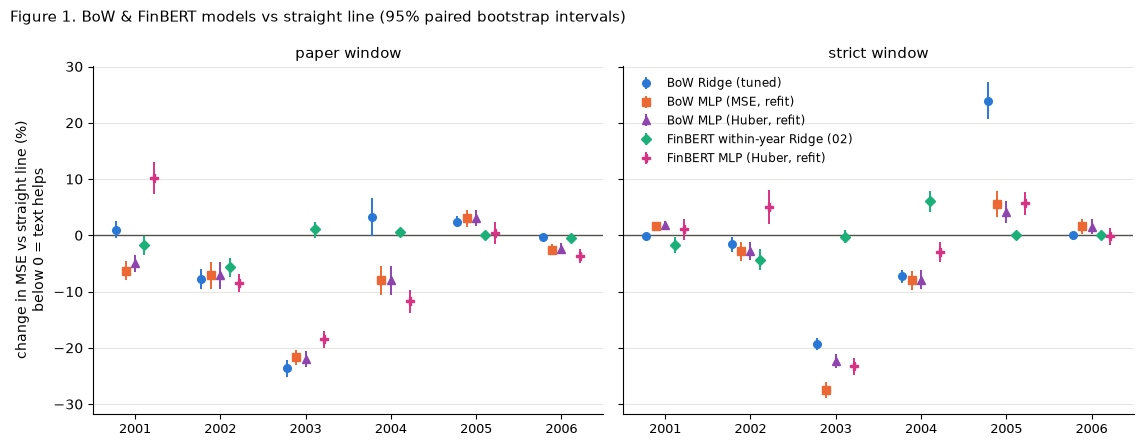

In [16]:
# Figure 1: Year-by-year comparison with 95% paired bootstrap intervals
COLORS = {
    "ridge: words + last year": "#2a78d6",
    ens_name("network: words + last year (refit)"): "#eb6834",
    ens_name("network: words + last year (Huber, refit)"): "#8e44ad",
    "within-year ridge, Item 7 (FinBERT, from 02)": "#1baf7a",
}
if X_FINBERT is not None:
    COLORS[ens_name("network: FinBERT + last year (Huber, refit)")] = "#d63384"

MARKERS = dict(zip(COLORS, ["o", "s", "^", "D", "P"]))
OFFSET = dict(zip(COLORS, np.linspace(-0.22, 0.22, len(COLORS))))
LABELS = {
    "ridge: words + last year": "BoW Ridge (tuned)",
    ens_name("network: words + last year (refit)"): "BoW MLP (MSE, refit)",
    ens_name("network: words + last year (Huber, refit)"): "BoW MLP (Huber, refit)",
    "within-year ridge, Item 7 (FinBERT, from 02)": "FinBERT within-year Ridge (02)",
    ens_name("network: FinBERT + last year (Huber, refit)"): "FinBERT MLP (Huber, refit)",
}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
for ax, window in zip(axes, scoring.WINDOWS):
    ax.axhline(0, color="#52514e", lw=1)
    for name in COLORS:
        r = shown[(shown.model == name) & (shown.window == window)]
        if r.empty:
            continue
        pct, lo, hi = r.change_pct, 100 * r.ci_low / r.baseline_mse, 100 * r.ci_high / r.baseline_mse
        ax.errorbar(r.test_year + OFFSET[name], pct, yerr=[pct - lo, hi - pct],
                    fmt=MARKERS[name], color=COLORS[name], ms=5.5, lw=1.4, capsize=0, label=LABELS[name])
    ax.set_title(f"{window} window", fontsize=11)
    ax.set_xticks(list(scoring.TEST_YEARS))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
axes[-1].legend(frameon=False, loc="best", fontsize=8.5)
fig.suptitle("Figure 1. BoW & FinBERT models vs straight line (95% paired bootstrap intervals)",
             fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [17]:
# Level vs. Spread decomposition (main window)
b_ = copy_vs_line[copy_vs_line.window == MAIN_WINDOW].set_index("test_year")
rows = {"line: level as % of its MSE": 100 * b_["baseline_level"] / b_["baseline_mse"]}
decomp_models = [
    "ridge: words + last year",
    ens_name("network: words + last year (refit)"),
    ens_name("network: words + last year (Huber, refit)"),
    ens_name("network: within-year words + last year (refit)"),
]
if X_FINBERT is not None:
    decomp_models += [
        ens_name("network: FinBERT + last year (refit)"),
        ens_name("network: FinBERT + last year (Huber, refit)"),
    ]
for name in decomp_models:
    r = results[(results.model == name) & (results.window == MAIN_WINDOW)].set_index("test_year")
    rows[f"{name}: level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name}: spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
ridge: words + last year: level,0.1,-4.4,-23.6,-6.0,1.9,0.1
ridge: words + last year: spread,0.9,-3.3,-0.0,9.3,0.5,-0.5
"network: words + last year (refit, 3 seeds averaged): level",-6.2,-4.1,-20.5,-8.4,2.6,-0.2
"network: words + last year (refit, 3 seeds averaged): spread",-0.1,-3.0,-1.2,0.4,0.4,-2.4
"network: words + last year (Huber, refit, 3 seeds averaged): level",-4.7,-4.1,-20.7,-8.4,2.5,-0.2
"network: words + last year (Huber, refit, 3 seeds averaged): spread",-0.3,-3.0,-1.3,0.4,0.5,-2.2
"network: within-year words + last year (refit, 3 seeds averaged): level",1.6,1.4,-14.4,-1.8,-0.0,0.5
"network: within-year words + last year (refit, 3 seeds averaged): spread",0.1,-2.6,1.8,0.6,0.1,-1.2
"network: FinBERT + last year (refit, 3 seeds averaged): level",8.0,-3.5,-14.1,-7.7,2.3,0.1


In [18]:
# Takeover sensitivity table (evaluates 3-seed averaged ensembles directly)
def split_preds(window, T):
    train, test = (as_mask(m) for m in scoring.masks(df, T, window))
    p = dict(fit_split(train, test))
    a, b = scoring.fit_line(df, train)
    p["copy last year"], p["straight line"] = prev[test], a + b * prev[test]
    return y[test], p

rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        yt, p = split_preds(window, T)
        keep = yt >= VERY_LOW
        for name, pt in p.items():
            if ", seed " in name:
                continue
            rows.append({
                "window": window, "test_year": T, "model": name,
                "test_mse": mse(yt, pt),
                "test_mse_excl_takeovers": mse(yt[keep], pt[keep]),
                "takeover_share": 1 - keep.mean(),
            })

tk = (pd.DataFrame(rows).groupby(["window", "model"], sort=False)
      .agg(test_mse=("test_mse", "mean"),
           test_mse_excl_takeovers=("test_mse_excl_takeovers", "mean"),
           reports_dropped=("takeover_share", lambda s: f"{s.mean():.1%}")))
tk.round(3)

test_mse  \
window model                                                          
paper  train mean                                             0.399   
       ridge: words only                                      0.159   
       ridge: words + last year                               0.119   
       network: words only (refit, 3 seeds averaged)          0.153   
       network: words + last year (no refit, 3 seeds a...     0.120   
       network: words + last year (refit, 3 seeds aver...     0.116   
       network: words + last year (Huber, refit, 3 see...     0.116   
       network: within-year words + last year (refit, ...     0.123   
       network: FinBERT + last year (refit, 3 seeds av...     0.120   
       network: FinBERT + last year (Huber, refit, 3 s...     0.120   
       copy last year                                         0.124   
       straight line                                          0.127   
strict train mean                                             0.442   
       ridge: words only                                      0.214   
       ridge: words + last year                               0.129   
       network: words only (refit, 3 seeds averaged)          0.215   
       network: words + last year (no refit, 3 seeds a...     0.139   
       network: words + last year (refit, 3 seeds aver...     0.124   
       network: words + last year (Huber, refit, 3 see...     0.126   
       network: within-year words + last year (refit, ...     0.133   
       network: FinBERT + last year (refit, 3 seeds av...     0.129   
       network: FinBERT + last year (Huber, refit, 3 s...     0.128   
       copy last year                                         0.124   
       straight line                                          0.133   

                                                           test_mse_excl_takeovers  \
window model                                                                         
paper  train mean                                                            0.381   
       ridge: words only                                                     0.144   
       ridge: words + last year                                              0.105   
       network: words only (refit, 3 seeds averaged)                         0.138   
       network: words + last year (no refit, 3 seeds a...                    0.105   
       network: words + last year (refit, 3 seeds aver...                    0.102   
       network: words + last year (Huber, refit, 3 see...                    0.102   
       network: within-year words + last year (refit, ...                    0.108   
       network: FinBERT + last year (refit, 3 seeds av...                    0.105   
       network: FinBERT + last year (Huber, refit, 3 s...                    0.105   
       copy last year                                                        0.109   
       straight line                                                         0.112   
strict train mean                                                            0.423   
       ridge: words only                                                     0.197   
       ridge: words + last year                                              0.114   
       network: words only (refit, 3 seeds averaged)                         0.199   
       network: words + last year (no refit, 3 seeds a...                    0.124   
       network: words + last year (refit, 3 seeds aver...                    0.109   
       network: words + last year (Huber, refit, 3 see...                    0.111   
       network: within-year words + last year (refit, ...                    0.118   
       network: FinBERT + last year (refit, 3 seeds av...                    0.115   
       network: FinBERT + last year (Huber, refit, 3 s...                    0.113   
       copy last year                                                        0.109   
       straight line                                          

## 5.8 — Which Words Does It Use? (3-Seed Ensemble Attribution)

In [19]:
T_LAST = max(scoring.TEST_YEARS)
M = MODELS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
S_last = make_split(*scoring.masks(df, T_LAST, MAIN_WINDOW))
assert (S_last.cols_full == M["cols"]).all(), "features were rebuilt differently from the fit"
words = vocab[M["cols"]]
word_index = {w: j for j, w in enumerate(words)}
print(f"window {MAIN_WINDOW}, test year {T_LAST}: train {KEY_OF[(MAIN_WINDOW, T_LAST)][0][0]}-{KEY_OF[(MAIN_WINDOW, T_LAST)][0][-1]}")

coef = M["ridge_text"].coef_
order_ = np.argsort(coef)
print("ridge, words only -- push volatility DOWN:", words[order_[:15]].tolist())
print("ridge, words only -- push volatility UP:  ", words[order_[::-1][:15]].tolist())

rng = np.random.default_rng(0)
sample = rng.choice(S_last.te_idx, size=min(2000, len(S_last.te_idx)), replace=False)
X_last_t = to_dense_tensor(S_last.X_full)
prev_last_t = torch.from_numpy(S_last.prev_z_full).to(device)
attr = np.zeros(S_last.X_full.shape[1])

for model in M["nets"]:
    model.eval()
    for i in range(0, len(sample), 500):
        r = sample[i:i + 500]
        model.zero_grad(set_to_none=True)
        xb = X_last_t[S_last.pos_full[r]].clone().detach().requires_grad_(True)
        model(xb, prev_last_t[r]).sum().backward()
        attr += (xb.grad * xb).sum(dim=0).detach().cpu().numpy()

attr /= (len(sample) * len(M["nets"]))
order_ = np.argsort(attr)
print("\nnetwork (3-seed refit ensemble), words + last year -- push prediction DOWN:", words[order_[:15]].tolist())
print("network (3-seed refit ensemble), words + last year -- push prediction UP:  ", words[order_[::-1][:15]].tolist())
del X_last_t
gc.collect()

window paper, test year 2006: train 2001-2005
ridge, words only -- push volatility DOWN: ['sharebased', 'dividends', 'esop', 'unsecured', 'policies', 'regulated', 'ferc', 'acquisitions', 'repurchase', 'timing', 'warmer', 'largely', 'distributions', 'coal', 'acquire']
ridge, words only -- push volatility UP:   ['loss', 'nasdaq', 'doubt', 'concern', 'raise', 'financing', 'debenture', 'going', 'smallcap', 'extraordinary', 'reciprocal', 'longlived', 'managements', 'personnel', 'default']

network (3-seed refit ensemble), words + last year -- push prediction DOWN: ['contents', 'stockbased', 'improved', 'billion', 'rate', 'corrections', 'previously', 'eitf', 'contributed', 'repurchase', 'banking', 'earnings', 'timing', 'classified', 'disclosure']
network (3-seed refit ensemble), words + last year -- push prediction UP:   ['sarbanesoxley', 'sharebased', 'loss', 'longlived', 'lease', 'financing', 'vesting', 'administrative', 'fsp', 'impairment', 'sfas', 'prices', 'supersedes', 'similar', 'obli

42

## 5.9 — Parallelism, Hashing Vectorization & 1,000× Scaling Benchmark

This section benchmarks four scaling dimensions relevant to a 1,000× production deployment (~27M filings):
1. **Data-volume scaling & learning curve** (`10%, 25%, 50%, 100%` of `S_last.fit_idx`).
2. **Batching bottleneck (Sparse-per-batch vs. Pre-materialized Dense)** and **CPU strong scaling** across `1, 2, 4` (and `8`, if available) PyTorch threads.
3. **Stateless Map-Only `HashingVectorizer` vs. Map-Reduce `CountVectorizer` + Global IDF:** Compares tokenization wall-clock time and memory on `T_LAST` (`~3,003` reports) without requiring a global vocabulary reduce step.
4. **1,000× back-of-envelope extrapolation** comparing single-machine limits against distributed Spark/Dask + multi-GPU data parallelism.

Batching speedup (pre-dense vs sparse-per-batch): 0.139s -> 0.105s (1.32x faster)


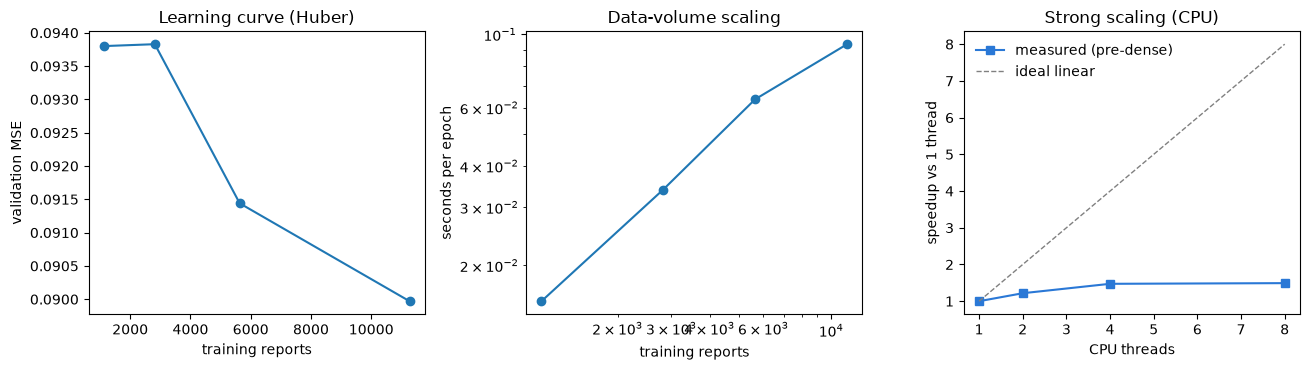

log-log slope of seconds per epoch vs training reports: 0.79 (1.0 = linear)


,fraction,n_train,best_epoch,val_mse,sec_per_epoch,total_seconds
0,0.10,1127,3,0.0938,0.0156,0.2259
1,0.25,2817,1,0.0938,0.0339,0.2888
2,0.50,5635,10,0.0914,0.0636,1.1760
3,1.00,11271,5,0.0900,0.0934,1.0978


,threads,sec_per_epoch,speedup
0,1,0.157,1.000
1,2,0.129,1.217
2,4,0.107,1.474
3,8,0.105,1.492


,method,n_reports,seconds,reports_per_sec,csr_MB,needs_global_vocab
0,CountVectorizer + TF-IDF (Map-Reduce),3003,14.008,214.378,26.387,True
1,HashingVectorizer (Stateless Map-Only),3003,13.674,219.617,25.923,False


4271

In [20]:
# 1. Learning curve & data-volume scaling (using fast pre-materialized dense tensor)
X_last_tune_t = to_dense_tensor(S_last.X_tune)
y_last_fit_t = torch.from_numpy(S_last.y_z_fit).to(device)
prev_last_fit_t = torch.from_numpy(S_last.prev_z_fit).to(device)

rng = np.random.default_rng(0)
lc_rows = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = S_last.fit_idx if frac == 1.0 else rng.choice(S_last.fit_idx, size=int(frac * len(S_last.fit_idx)), replace=False)
    t0 = time.perf_counter()
    _, hist, bep = train_nn_fast(
        X_last_tune_t, S_last.pos_tune, y_last_fit_t, prev_last_fit_t, sub, S_last.val_idx, S_last.sd_fit,
        use_prev=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
        loss_type="huber", huber_delta=HUBER_DELTA, use_val=True
    )
    lc_rows.append({
        "fraction": frac, "n_train": len(sub), "best_epoch": bep,
        "val_mse": hist["val_mse"].min(),
        "sec_per_epoch": hist["seconds"].mean(),
        "total_seconds": time.perf_counter() - t0,
    })
lc = pd.DataFrame(lc_rows)

# 2. Sparse-per-batch vs Pre-materialized Dense & CPU Strong Scaling
def bench_sparse_epoch(S_obj, n_epochs=3):
    torch.manual_seed(0)
    rng_ = np.random.default_rng(0)
    m = ResidualTextNet(S_obj.X_tune.shape[1], hidden=HIDDEN, dropout=DROPOUT, use_prev=True).to(device)
    opt = make_optimizer(m)
    loss_fn = make_loss("huber", HUBER_DELTA)
    secs = []
    for _ in range(n_epochs):
        t0 = time.perf_counter()
        order_ = rng_.permutation(S_obj.fit_idx)
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            xb = torch.from_numpy(S_obj.X_tune[S_obj.pos_tune[r]].toarray()).to(device)
            loss = loss_fn(m(xb, prev_last_fit_t[r]), y_last_fit_t[r])
            loss.backward()
            opt.step()
        secs.append(time.perf_counter() - t0)
    return float(np.mean(secs))

sparse_sec = bench_sparse_epoch(S_last, n_epochs=3)

orig_threads = torch.get_num_threads()
max_cores = os.cpu_count() or 4
thread_counts = sorted({t for t in [1, 2, 4, 8] if t <= max_cores})
thread_rows = []
for n_th in thread_counts:
    torch.set_num_threads(n_th)
    _, hist_th, _ = train_nn_fast(
        X_last_tune_t, S_last.pos_tune, y_last_fit_t, prev_last_fit_t,
        S_last.fit_idx, S_last.val_idx, S_last.sd_fit,
        use_prev=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
        loss_type="huber", huber_delta=HUBER_DELTA, max_epochs=5, use_val=False
    )
    thread_rows.append({"threads": n_th, "sec_per_epoch": hist_th["seconds"].mean()})
torch.set_num_threads(orig_threads)

th_df = pd.DataFrame(thread_rows)
th_df["speedup"] = th_df["sec_per_epoch"].iloc[0] / th_df["sec_per_epoch"]
print(f"Batching speedup (pre-dense vs sparse-per-batch): {sparse_sec:.3f}s -> {th_df['sec_per_epoch'].min():.3f}s "
      f"({sparse_sec / th_df['sec_per_epoch'].min():.2f}x faster)")

# 3. Stateless HashingVectorizer vs CountVectorizer + TfidfTransformer benchmark on T_LAST texts
texts_last = load_year_texts(T_LAST)

t0 = time.perf_counter()
cv = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, max_features=N_WORDS, dtype=np.int32)
X_cv = TfidfTransformer(sublinear_tf=True).fit_transform(cv.fit_transform(texts_last)).astype(np.float32)
t_cv = time.perf_counter() - t0
bytes_cv = X_cv.data.nbytes + X_cv.indices.nbytes + X_cv.indptr.nbytes

t0 = time.perf_counter()
hv = HashingVectorizer(n_features=N_WORDS, stop_words="english", token_pattern=TOKEN,
                       alternate_sign=False, norm="l2", dtype=np.float32)
X_hv = hv.transform(texts_last)
t_hv = time.perf_counter() - t0
bytes_hv = X_hv.data.nbytes + X_hv.indices.nbytes + X_hv.indptr.nbytes

vec_bench = pd.DataFrame([
    {"method": "CountVectorizer + TF-IDF (Map-Reduce)", "n_reports": len(texts_last),
     "seconds": t_cv, "reports_per_sec": len(texts_last) / t_cv,
     "csr_MB": bytes_cv / 1e6, "needs_global_vocab": True},
    {"method": "HashingVectorizer (Stateless Map-Only)", "n_reports": len(texts_last),
     "seconds": t_hv, "reports_per_sec": len(texts_last) / t_hv,
     "csr_MB": bytes_hv / 1e6, "needs_global_vocab": False},
])

# Plots
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8))
axes[0].plot(lc["n_train"], lc["val_mse"], "o-")
axes[0].set_xlabel("training reports"); axes[0].set_ylabel("validation MSE"); axes[0].set_title("Learning curve (Huber)")

axes[1].loglog(lc["n_train"], lc["sec_per_epoch"], "o-")
axes[1].set_xlabel("training reports"); axes[1].set_ylabel("seconds per epoch"); axes[1].set_title("Data-volume scaling")

axes[2].plot(th_df["threads"], th_df["speedup"], "s-", color="#2a78d6", label="measured (pre-dense)")
axes[2].plot(th_df["threads"], th_df["threads"], "--", color="grey", lw=1, label="ideal linear")
axes[2].set_xlabel("CPU threads"); axes[2].set_ylabel("speedup vs 1 thread"); axes[2].set_title("Strong scaling (CPU)")
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

slope_time = np.polyfit(np.log(lc["n_train"]), np.log(lc["sec_per_epoch"]), 1)[0]
print(f"log-log slope of seconds per epoch vs training reports: {slope_time:.2f} (1.0 = linear)")
display(lc.round(4))
display(th_df.round(3))
display(vec_bench.round(3))

del X_last_tune_t
gc.collect()

In [21]:
# 4. 1,000x back-of-envelope extrapolation
FACTOR = 1000
full = lc.iloc[-1]
csr_bytes = S_last.X_full.data.nbytes + S_last.X_full.indices.nbytes + S_last.X_full.indptr.nbytes
n_params = sum(p.numel() for p in M["nets"][0].parameters())
count_secs = timings["count_seconds"]

print(f"reports: {len(df):,}  ->  {len(df) * FACTOR:,.0f}")
print(f"sparse feature table (one split): {csr_bytes / 1e6:,.0f} MB  ->  {csr_bytes * FACTOR / 1e9:,.0f} GB "
      f"({csr_bytes / S_last.X_full.shape[0] / 1e3:.1f} kB per report)")
print(f"counting words (one pass, one core): {count_secs / 60:,.1f} min  ->  {count_secs * FACTOR / 3600:,.0f} hours")
print(f"one training epoch (pre-dense CPU): {full['sec_per_epoch']:.3f} s  ->  {full['sec_per_epoch'] * FACTOR / 3600:,.2f} hours (linear)")
print(f"network parameters: {n_params:,} (fixed by N_WORDS={N_WORDS} and HIDDEN={HIDDEN}, independent of N)")

reports: 27,142  ->  27,142,000
sparse feature table (one split): 141 MB  ->  141 GB (8.1 kB per report)
counting words (one pass, one core): 1.5 min  ->  25 hours
one training epoch (pre-dense CPU): 0.093 s  ->  0.03 hours (linear)
network parameters: 80,035 (fixed by N_WORDS=5000 and HIDDEN=16, independent of N)


## 5.10 — Conclusions & Interpretations *(To Be Written After Running)*

- **2 × 2 Comparison (BoW vs. FinBERT × Ridge vs. MLP):** Summarize whether neural non-linearity adds further gains on top of dense FinBERT embeddings, or whether BoW-MLP (Huber, refit) remains competitive.
- **Huber $\delta$ sensitivity:** Discuss the trade-off between clipping takeover outliers (`logvol_after < -5`) and preserving quadratic accuracy on normal firms.
- **CPU speedup & scaling:** Contrast sparse-per-batch vs. pre-dense epoch times, CPU strong scaling, and Map-Reduce `CountVectorizer` vs. stateless Map-only `HashingVectorizer` at 1,000× scale.